# SST forecasting from an eleven-channel state

This notebook presents the formal sea-surface-temperature (SST) experiment on daily $64\times32$ fields from **1993-01-01 through 2022-12-31**. The model receives eleven fields observed at the same time, advances the augmented state autonomously, and is evaluated **only on SST**.

The input channels are SST, zonal and meridional wind stress, sea-surface height, potential temperature at 55 m and 105 m, zonal and meridional current at 5 m, mixed-layer depth, salinity at 5 m, and total downward surface heat flux.

The chronological protocol is fixed:

- **Validation:** fit on 1993-01-01 through 2016-12-31; evaluate on 2017-01-01 through 2019-12-31.
- **Evaluation:** fit on 1993-01-01 through 2019-12-31; evaluate on the held-out 2020-01-01 through 2022-12-31 period.

The two fitting windows contain 8,764 and 9,859 distinct complete `(t,t+1,t+2)` training starts, respectively. All normalization, climatology, EOF bases, and learned model parameters are estimated from the applicable fitting window only; the fixed configuration is established before the held-out evaluation period.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from plotting_utils import print_figure_caption
from project_paths import FIGURES_DIR, PROJECT_ROOT, RESULTS_DIR


CHANNELS = (
    "sst",
    "wind_stress_x",
    "wind_stress_y",
    "ssh",
    "temp_55m",
    "temp_105m",
    "current_5m_u",
    "current_5m_v",
    "mld",
    "salinity_5m",
    "q_net",
)

DATE_PROTOCOL = {
    "record": ("1993-01-01", "2022-12-31"),
    "validation_fit": ("1993-01-01", "2016-12-31"),
    "validation_evaluation": ("2017-01-01", "2019-12-31"),
    "evaluation_fit": ("1993-01-01", "2019-12-31"),
    "evaluation_period": ("2020-01-01", "2022-12-31"),
}

FIXED_PARAMETERS = {
    "seed": 2026,
    "sst_weight": 0.5,
    "eof_sst": 64,
    "eof_aux": 4,
    "aux_harmonics": 6,
    "width": 96,
    "layers": 4,
    "modes": (12, 24),
    "epochs": 180,
    "learning_rate": 5e-4,
    "batch_size": 12,
    "sg_weight": 0.25,
    "mix_augment": 0.5,
    "rank": 96,
    "ridge": 1e-2,
    "alpha_data": 0.6,
    "stabilize_max_radius": 0.9975,
    "residual_mode": "scalar_ar1",
}

# Every figure-size, spacing, typography, and legend control is centralized here.
PLOT_STYLE = {
    "figsize": (13.2, 8.8),
    "left": 0.075,
    "right": 0.985,
    "bottom": 0.085,
    "top": 0.805,
    "wspace": 0.245,
    "hspace": 0.38,
    "suptitle_y": 0.980,
    "legend_y": 0.908,
    "legend_ncol": 3,
    "dpi": 300,
    "suptitle_size": 17,
    "title_size": 14,
    "axis_label_size": 12,
    "tick_label_size": 10,
    "legend_size": 14,
    "line_width": 2.0,
    "marker_size": 3.0,
    "grid_alpha": 0.25,
}

METHOD_ORDER = ("fno", "sfno", "bso", "damped_persistence", "raw_persistence", "climatology")
# Matplotlib fills multi-column legends by column. This interleaving renders
# METHOD_ORDER row-wise as: model methods on row 1, reference methods on row 2.
LEGEND_ORDER = ("fno", "damped_persistence", "sfno", "raw_persistence", "bso", "climatology")
METHOD_LABELS = {
    "fno": "FNO",
    "sfno": "SFNO",
    "bso": "BSO",
    "damped_persistence": "Damped persistence",
    "raw_persistence": "Persistence",
    "climatology": "Calendar-day climatology",
}
METHOD_COLORS = {
    "fno": "#0072B2",
    "sfno": "#009E73",
    "bso": "#D55E00",
    "damped_persistence": "#6B7280",
    "raw_persistence": "#A3A3A3",
    "climatology": "#CC79A7",
}
METHOD_STYLES = {
    "fno": "-",
    "sfno": "-",
    "bso": "-",
    "damped_persistence": "--",
    "raw_persistence": "-.",
    "climatology": ":",
}

print("Target: SST only")
print("Input channels:", len(CHANNELS))
print(json.dumps(FIXED_PARAMETERS, indent=2))

Target: SST only
Input channels: 11
{
  "seed": 2026,
  "sst_weight": 0.5,
  "eof_sst": 64,
  "eof_aux": 4,
  "aux_harmonics": 6,
  "width": 96,
  "layers": 4,
  "modes": [
    12,
    24
  ],
  "epochs": 180,
  "learning_rate": 0.0005,
  "batch_size": 12,
  "sg_weight": 0.25,
  "mix_augment": 0.5,
  "rank": 96,
  "ridge": 0.01,
  "alpha_data": 0.6,
  "stabilize_max_radius": 0.9975,
  "residual_mode": "scalar_ar1"
}


## Method and result contract

The raw one-day FNO uses a four-layer width-96 network with Fourier modes $(12,24)$. BSO keeps that raw FNO input domain unchanged and uses a training-only structured anomaly representation with 64 SST EOFs, four EOFs per auxiliary channel, six auxiliary calendar harmonics, and a rank-96 joint projection. Its one-step target blends observed and frozen-FNO coordinates with `alpha_data = 0.6`, followed by real-Schur stabilization at radius 0.9975. Formal forecast skill is evaluated over days 1--90 against direct FNO/SFNO and lead-appropriate persistence/climatology baselines. A separate 540-day BSO/FNO/SFNO stress test assesses numerical rollout stability only.

This notebook is presentation-only: it does not train a model or reconstruct missing scores. It reads `results/sst/latest_result.json`, resolves the metric artifact recorded there, and copies numerical arrays into memory. The artifact may contain any subset of the listed methods; unavailable series are omitted automatically.

In [ ]:
RESULT_INDEX = RESULTS_DIR / 'sst' / 'latest_result.json'
METRIC_NAMES = ("rmse", "mae", "acc", "bias", "std_ratio")

latest_result = None
metrics_source = None
leads = None
metric_data = {}


def _display_path(path):
    path = Path(path).resolve()
    try:
        return path.relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return str(path)


def _as_numeric_vector(value):
    array = np.asarray(value, dtype=np.float64).reshape(-1)
    return array.copy()


def _add_path_value(raw_paths, value, filename=None):
    if isinstance(value, dict):
        value = value.get("path")
    if not isinstance(value, (str, Path)):
        return
    path = Path(value)
    if filename is not None:
        path = path / filename
    raw_paths.append(path)


def _metric_path_candidates(manifest):
    raw_paths = []
    sections = [manifest]
    artifacts = manifest.get("artifacts")
    if isinstance(artifacts, dict):
        sections.append(artifacts)
    outputs = manifest.get("outputs")
    if isinstance(outputs, dict):
        sections.append(outputs)

    for section in sections:
        for key in ("metrics", "metrics_path", "forecast_metrics", "forecast_metrics_path"):
            _add_path_value(raw_paths, section.get(key))
        for key in ("result_dir", "run_dir", "artifact_dir"):
            _add_path_value(raw_paths, section.get(key), "forecast_metrics.npz")

    candidates = []
    seen = set()
    for raw_path in raw_paths:
        expanded = [raw_path] if raw_path.is_absolute() else [
            PROJECT_ROOT / raw_path,
            RESULT_INDEX.parent / raw_path,
        ]
        for path in expanded:
            normalized = path.resolve()
            key = str(normalized)
            if key not in seen:
                seen.add(key)
                candidates.append(normalized)
    return candidates


def _artifact_path_candidates(manifest, artifact_key):
    raw_paths = []
    sections = [manifest]
    for section_name in ("artifacts", "outputs"):
        section = manifest.get(section_name)
        if isinstance(section, dict):
            sections.append(section)
    for section in sections:
        _add_path_value(raw_paths, section.get(artifact_key))

    candidates = []
    seen = set()
    for raw_path in raw_paths:
        expanded = [raw_path] if raw_path.is_absolute() else [
            PROJECT_ROOT / raw_path,
            RESULT_INDEX.parent / raw_path,
        ]
        for path in expanded:
            normalized = path.resolve()
            key = str(normalized)
            if key not in seen:
                seen.add(key)
                candidates.append(normalized)
    return candidates


def _read_metric_archive(path):
    loaded = {}
    loaded_leads = None
    with np.load(path, allow_pickle=False) as archive:
        if "leads" in archive.files:
            loaded_leads = _as_numeric_vector(archive["leads"])
        for metric in METRIC_NAMES:
            by_method = {}
            for method in METHOD_ORDER:
                key = f"{metric}_{method}"
                if key in archive.files:
                    by_method[method] = _as_numeric_vector(archive[key])
            if by_method:
                loaded[metric] = by_method
    return loaded_leads, loaded


def _read_embedded_metrics(manifest):
    embedded = manifest.get("metrics")
    if not isinstance(embedded, dict):
        return None, {}

    embedded_leads = manifest.get("leads", embedded.get("leads"))
    parsed_leads = None if embedded_leads is None else _as_numeric_vector(embedded_leads)
    parsed = {}
    for metric in METRIC_NAMES:
        by_method = embedded.get(metric)
        if not isinstance(by_method, dict):
            continue
        parsed_methods = {
            method: _as_numeric_vector(by_method[method])
            for method in METHOD_ORDER
            if method in by_method
        }
        if parsed_methods:
            parsed[metric] = parsed_methods
    return parsed_leads, parsed


if not RESULT_INDEX.is_file():
    print(
        f"No result index found at {_display_path(RESULT_INDEX)}. "
        "Complete the locked evaluation; it creates this index automatically."
    )
else:
    latest_result = json.loads(RESULT_INDEX.read_text(encoding="utf-8"))
    for candidate in _metric_path_candidates(latest_result):
        if candidate.is_file():
            metrics_source = candidate
            leads, metric_data = _read_metric_archive(candidate)
            break

    if not metric_data:
        embedded_leads, embedded_data = _read_embedded_metrics(latest_result)
        if embedded_data:
            leads, metric_data = embedded_leads, embedded_data
            metrics_source = RESULT_INDEX

    if leads is None or not metric_data:
        print(
            "The result index was read, but it does not resolve to usable lead and metric arrays."
        )
    else:
        available_methods = [
            method
            for method in METHOD_ORDER
            if any(method in metric_data.get(metric, {}) for metric in METRIC_NAMES)
        ]
        print("Loaded metrics from:", _display_path(metrics_source))
        print("Available methods:", ", ".join(METHOD_LABELS[m] for m in available_methods))
        print("Lead range:", f"{np.nanmin(leads):g} to {np.nanmax(leads):g} days")

Loaded metrics from: results/sst/evaluation/sst-forecast-90d-stability-540d-seed2026/forecast_metrics.npz
Available methods: FNO, SFNO, BSO, Damped persistence, Persistence, Calendar-day climatology
Lead range: 1 to 90 days


## SST-only forecast verification

All scores use ocean-mask and latitude weighting. RMSE and MAE measure physical SST error in kelvin, while centered anomaly ACC measures pattern skill relative to training-only target-date climatology. This figure is restricted to the 1--90-day forecast-skill protocol. The separate 540-day learned-model stress-test figure is based on `stability_metrics.npz` and is not interpreted as long-range forecast skill.

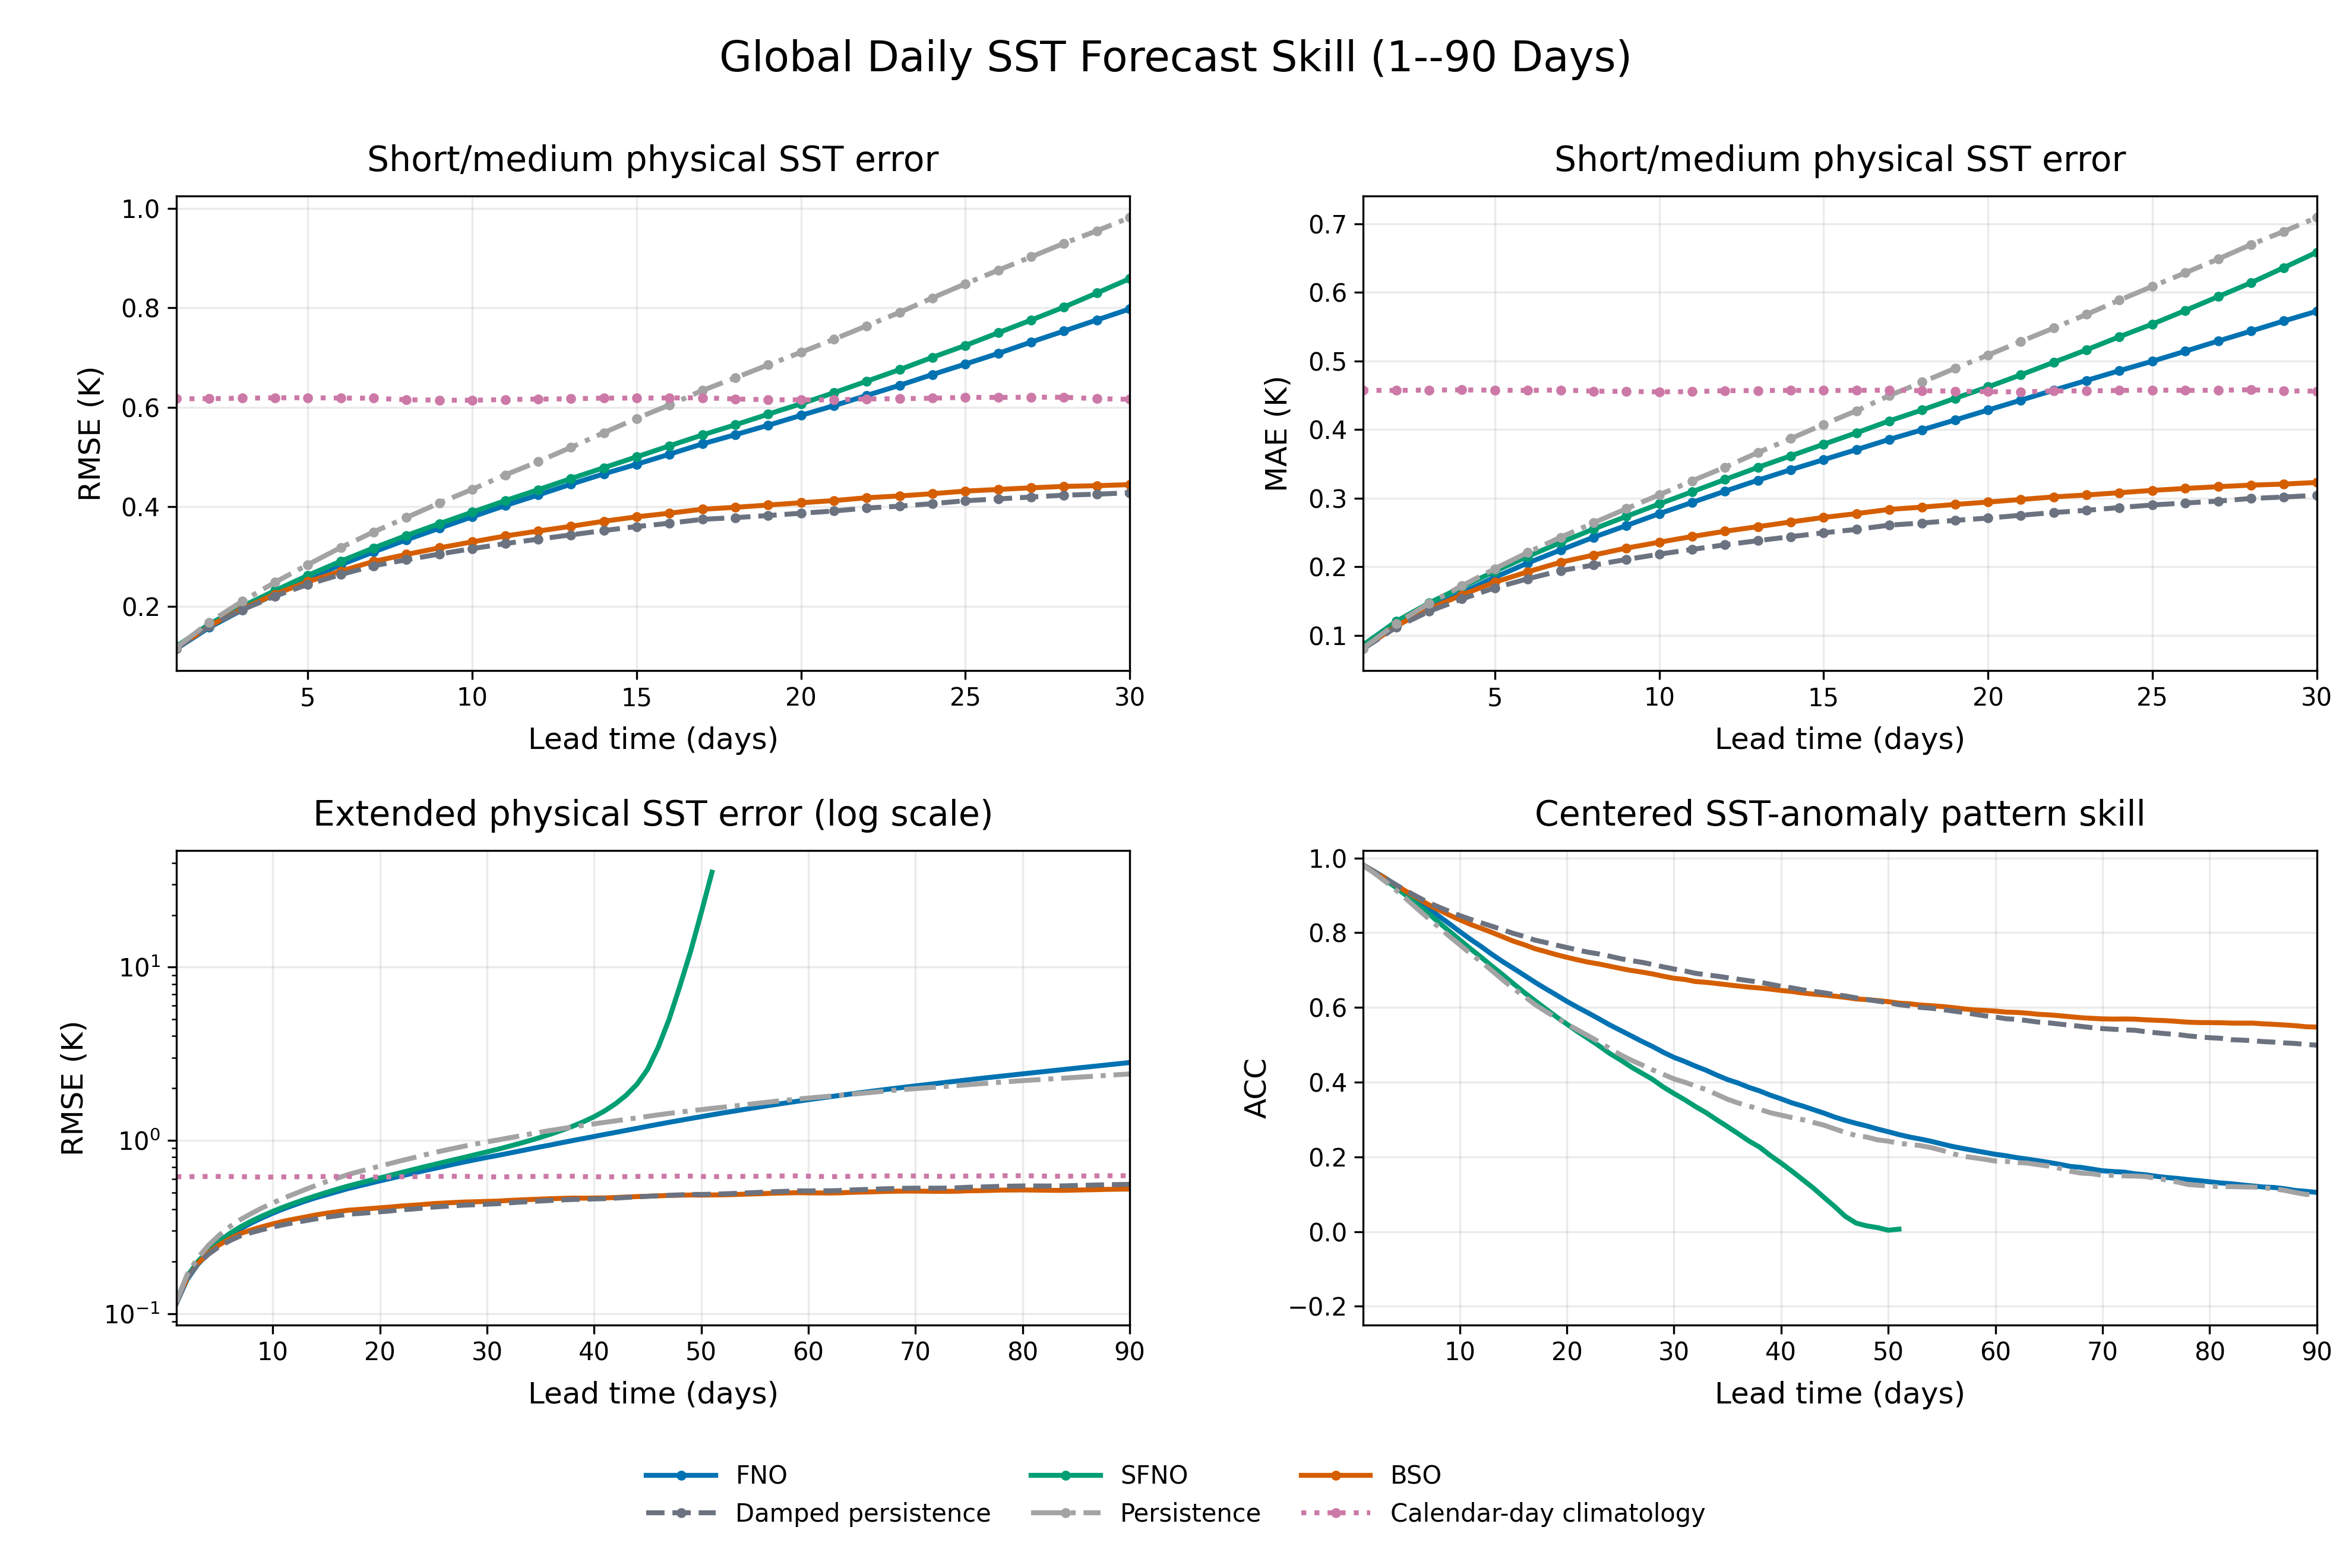


Figure caption:
Global SST forecast skill over 96 held-out 2020--2022 origins after fitting on 1993--2019. Eleven ocean--atmosphere fields initialize learned methods, but only SST is verified. Panels show area-weighted RMSE and MAE through day 30, and RMSE and centered anomaly ACC through day 90. BSO is competitive with damped persistence at short leads and best among complete-band methods over days 31--90; SFNO ends when complete-cohort scores become unavailable.
Saved: figures/sst/sst_forecast_skill.png
Saved: figures/sst/sst_forecast_skill.pdf
Saved: figures/sst/sst_forecast_skill_caption.txt


In [ ]:
FIGURE_DIR = FIGURES_DIR / 'sst'
PANEL_SPECS = (
    ("rmse", "Short/medium physical SST error", "RMSE (K)", 30, None),
    ("mae", "Short/medium physical SST error", "MAE (K)", 30, None),
    ("rmse", "Extended physical SST error (log scale)", "RMSE (K)", 90, None),
    ("acc", "Centered SST-anomaly pattern skill", "ACC", 90, (-0.25, 1.02)),
)

CAPTION = (
    "Global SST forecast skill over 96 held-out 2020--2022 origins after fitting on "
    "1993--2019. Eleven ocean--atmosphere fields initialize learned methods, but only "
    "SST is verified. Panels show area-weighted RMSE and MAE through day 30, and RMSE "
    "and centered anomaly ACC through day 90. BSO is competitive with damped "
    "persistence at short leads and best among complete-band methods over days 31--90; "
    "SFNO ends when complete-cohort scores become unavailable."
)


def _finite_series(metric, method):
    values = np.asarray(metric_data[metric][method], dtype=np.float64).reshape(-1)
    count = min(leads.size, values.size)
    x = leads[:count]
    y = values[:count]
    finite = np.isfinite(x) & np.isfinite(y)
    return x[finite], y[finite]


if leads is None or not metric_data:
    reference_png = FIGURE_DIR / "sst_forecast_skill.png"
    if reference_png.is_file():
        display(Image(filename=str(reference_png)))
        print_figure_caption(CAPTION)
        print("Displayed the committed reference figure; numerical artifacts are not available.")
    else:
        print("No forecast figure was created because usable metrics are not available.")
else:
    fig, axes = plt.subplots(2, 2, figsize=PLOT_STYLE["figsize"], squeeze=False)
    fig.subplots_adjust(
        left=PLOT_STYLE["left"],
        right=PLOT_STYLE["right"],
        bottom=PLOT_STYLE["bottom"],
        top=PLOT_STYLE["top"],
        wspace=PLOT_STYLE["wspace"],
        hspace=PLOT_STYLE["hspace"],
    )

    for ax, (metric, title, ylabel, horizon, fixed_ylim) in zip(axes.flat, PANEL_SPECS):
        methods_here = [
            method for method in METHOD_ORDER if method in metric_data.get(metric, {})
        ]
        if metric == "acc":
            methods_here = [method for method in methods_here if method != "climatology"]
        if not methods_here:
            ax.set_visible(False)
            continue

        plotted_x = []
        for method in methods_here:
            x, y = _finite_series(metric, method)
            visible = x <= horizon
            if np.any(visible):
                x, y = x[visible], y[visible]
            if x.size == 0:
                continue
            plotted_x.append(x)
            ax.plot(
                x,
                y,
                color=METHOD_COLORS[method],
                linestyle=METHOD_STYLES[method],
                linewidth=PLOT_STYLE["line_width"],
                marker="o" if x.size <= 35 else None,
                markersize=PLOT_STYLE["marker_size"],
                label=METHOD_LABELS[method],
            )

        if not plotted_x:
            ax.set_visible(False)
            continue

        x_all = np.concatenate(plotted_x)
        x_min = max(0.0, float(np.nanmin(x_all)))
        x_max = min(float(horizon), float(np.nanmax(x_all)))
        if x_max > x_min:
            ax.set_xlim(x_min, x_max)
        if fixed_ylim is not None:
            ax.set_ylim(*fixed_ylim)
        if metric == "bias":
            ax.axhline(0.0, color="#111827", linewidth=0.9, alpha=0.6)
        if metric == "std_ratio":
            ax.axhline(1.0, color="#111827", linewidth=0.9, alpha=0.6)
        if metric == "rmse" and horizon == 90:
            ax.set_yscale("log")

        ax.set_title(title, fontsize=PLOT_STYLE["title_size"], pad=10)
        ax.set_xlabel("Lead time (days)", fontsize=PLOT_STYLE["axis_label_size"], labelpad=6)
        ax.set_ylabel(ylabel, fontsize=PLOT_STYLE["axis_label_size"], labelpad=6)
        ax.tick_params(axis="both", labelsize=PLOT_STYLE["tick_label_size"], pad=3)
        ax.grid(True, alpha=PLOT_STYLE["grid_alpha"])

    fig.suptitle(
        "Global Daily SST Forecast Skill (1--90 Days)",
        fontsize=PLOT_STYLE["suptitle_size"],
        y=PLOT_STYLE["suptitle_y"],
    )

    handles_by_label = {}
    for ax in axes.flat:
        if ax.get_visible():
            handles, labels = ax.get_legend_handles_labels()
            for handle, label in zip(handles, labels):
                handles_by_label.setdefault(label, handle)
    ordered_labels = [
        METHOD_LABELS[method]
        for method in LEGEND_ORDER
        if METHOD_LABELS[method] in handles_by_label
    ]
    if ordered_labels:
        fig.legend(
            [handles_by_label[label] for label in ordered_labels],
            ordered_labels,
            loc="center",
            bbox_to_anchor=(0.5, PLOT_STYLE["legend_y"]),
            ncol=min(PLOT_STYLE["legend_ncol"], len(ordered_labels)),
            frameon=False,
            fontsize=PLOT_STYLE["legend_size"],
            columnspacing=1.6,
            handlelength=2.8,
        )

    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    png_path = FIGURE_DIR / "sst_forecast_skill.png"
    pdf_path = FIGURE_DIR / "sst_forecast_skill.pdf"
    caption_path = FIGURE_DIR / "sst_forecast_skill_caption.txt"
    fig.savefig(png_path, dpi=PLOT_STYLE["dpi"], facecolor="white")
    fig.savefig(pdf_path, dpi=PLOT_STYLE["dpi"], facecolor="white")
    caption_path.write_text(CAPTION + "\n", encoding="utf-8")
    plt.close(fig)
    display(Image(filename=str(png_path)))
    print_figure_caption(CAPTION)
    print("Saved:", _display_path(png_path))
    print("Saved:", _display_path(pdf_path))
    print("Saved:", _display_path(caption_path))

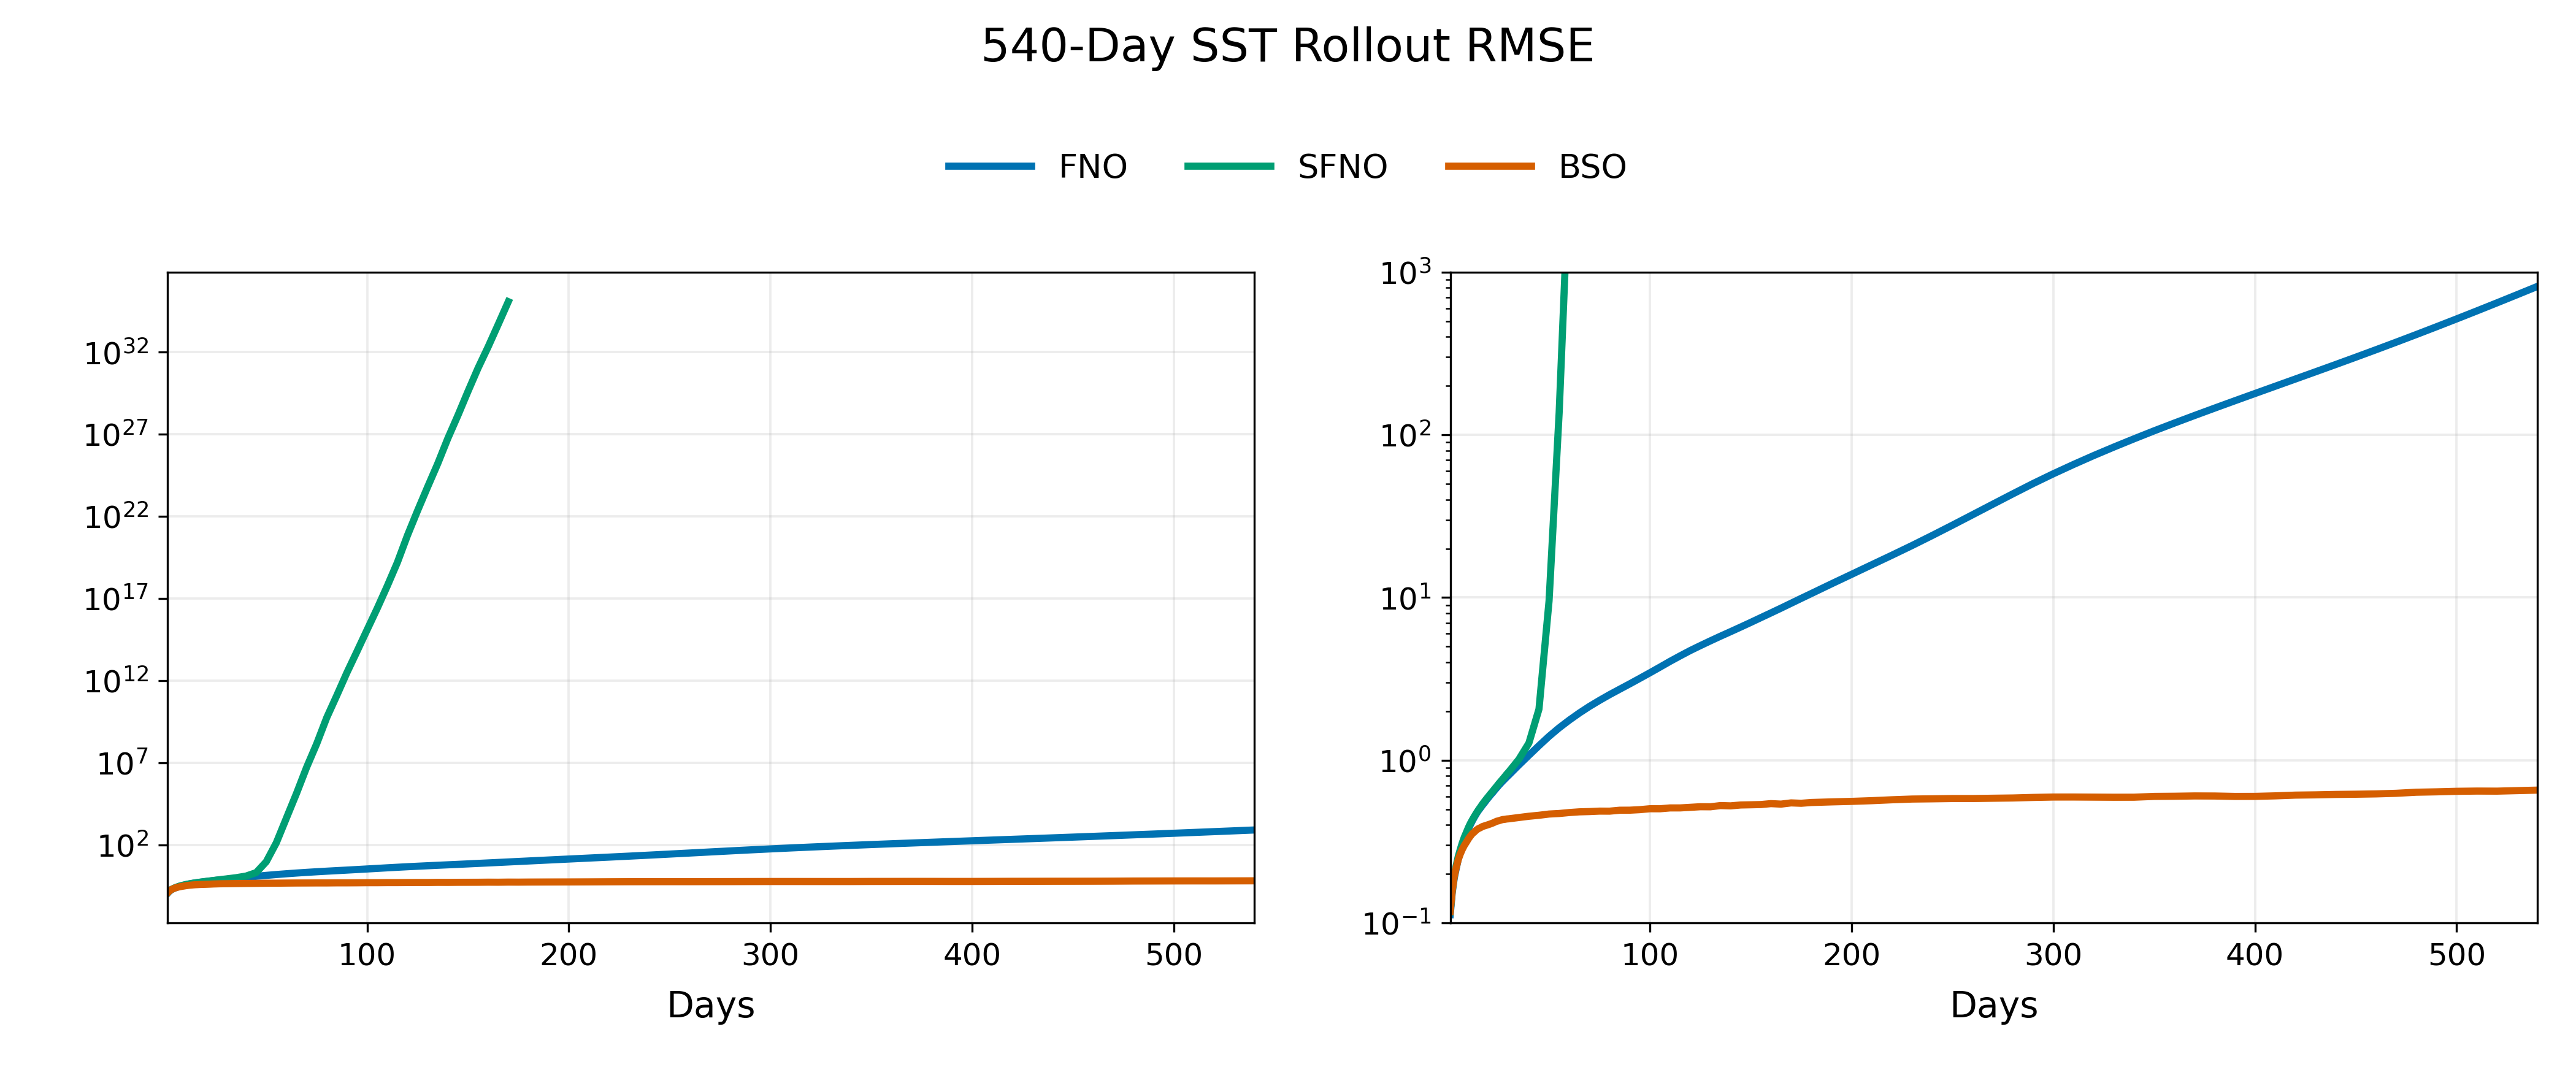


Figure caption:
Area-weighted physical SST RMSE in a 540-day numerical stability test over 48 origins, shown over full and zoomed logarithmic ranges. BSO remains bounded, FNO reaches 816.327 K at day 540, and SFNO becomes nonfinite at day 171. FNO/SFNO validity uses the full 11-channel state, whereas BSO uses decoded SST; this is not a long-range skill ranking.
Metric: area-weighted physical SST RMSE pooled over 48 origins (K, log scale).
FNO: last complete-cohort point = day 540, RMSE = 816.3269 K
SFNO: last complete-cohort point = day 170, RMSE = 1.2046e+35 K
BSO: last complete-cohort point = day 540, RMSE = 0.6551 K
Right-panel display range: 10^-1 to 10^3 K; larger values remain in the full-range panel and archive.
Finite values are retained regardless of magnitude; a curve stops only at NaN/Inf.
Saved: figures/sst/sst_rollout_stability.png
Saved: figures/sst/sst_rollout_stability.pdf
Saved: figures/sst/sst_rollout_stability_caption.txt


In [ ]:
STABILITY_STYLE = {
    "figsize": (14.0, 5.8),
    "left": 0.065,
    "right": 0.985,
    "bottom": 0.135,
    "top": 0.745,
    "wspace": 0.18,
    "title_size": 18,
    "axis_label_size": 14,
    "tick_label_size": 12,
    "legend_size": 14,
    "line_width": 2.8,
    "grid_alpha": 0.24,
    "dpi": 300,
}

STABILITY_CAPTION = (
    "Area-weighted physical SST RMSE in a 540-day numerical stability test over 48 "
    "origins, shown over full and zoomed logarithmic ranges. BSO remains bounded, FNO "
    "reaches 816.327 K at day 540, and SFNO becomes nonfinite at day 171. FNO/SFNO "
    "validity uses the full 11-channel state, whereas BSO uses decoded SST; this is not "
    "a long-range skill ranking."
)

stability_candidates = (
    [] if latest_result is None
    else _artifact_path_candidates(latest_result, "stability_metrics")
)
stability_path = next((path for path in stability_candidates if path.is_file()), None)
if stability_path is None:
    reference_stability_png = FIGURE_DIR / "sst_rollout_stability.png"
    if reference_stability_png.is_file():
        display(Image(filename=str(reference_stability_png)))
        print_figure_caption(STABILITY_CAPTION)
        print("Displayed the committed reference figure; numerical artifacts are not available.")
    else:
        print("No stability figure was created because the current result has no stability archive.")
else:
    with np.load(stability_path, allow_pickle=False) as archive:
        stability_leads = np.asarray(archive["leads"], dtype=np.float64)
        strict_rmse = {
            "fno": np.asarray(archive["rmse_fno"], dtype=np.float64),
            "sfno": np.asarray(archive["rmse_sfno"], dtype=np.float64),
            "bso": np.asarray(archive["rmse_bso"], dtype=np.float64),
        }

    fig, (ax_full, ax_zoom) = plt.subplots(
        1, 2, figsize=STABILITY_STYLE["figsize"], sharex=True,
    )
    fig.subplots_adjust(
        left=STABILITY_STYLE["left"], right=STABILITY_STYLE["right"],
        bottom=STABILITY_STYLE["bottom"], top=STABILITY_STYLE["top"],
        wspace=STABILITY_STYLE["wspace"],
    )

    for axis in (ax_full, ax_zoom):
        for method in ("fno", "sfno", "bso"):
            values = strict_rmse[method]
            finite = np.isfinite(values) & (values > 0.0)
            axis.plot(
                stability_leads[finite], values[finite],
                color=METHOD_COLORS[method],
                linewidth=STABILITY_STYLE["line_width"],
                label=METHOD_LABELS[method],
            )
        axis.set_yscale("log")
        axis.set_xlabel(
            "Days", fontsize=STABILITY_STYLE["axis_label_size"], labelpad=7,
        )
        axis.set_xlim(float(stability_leads.min()), float(stability_leads.max()))
        axis.tick_params(
            axis="both", labelsize=STABILITY_STYLE["tick_label_size"], pad=4,
        )
        axis.grid(True, alpha=STABILITY_STYLE["grid_alpha"], linewidth=0.9)

    ax_zoom.set_ylim(1.0e-1, 1.0e3)
    fig.suptitle(
        "540-Day SST Rollout RMSE",
        fontsize=STABILITY_STYLE["title_size"], y=0.975,
    )
    handles, labels = ax_full.get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.885),
        ncol=3, frameon=False,
        fontsize=STABILITY_STYLE["legend_size"], columnspacing=1.8,
        handlelength=2.5,
    )

    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    stability_png = FIGURE_DIR / "sst_rollout_stability.png"
    stability_pdf = FIGURE_DIR / "sst_rollout_stability.pdf"
    stability_caption = FIGURE_DIR / "sst_rollout_stability_caption.txt"
    fig.savefig(stability_png, dpi=STABILITY_STYLE["dpi"], facecolor="white")
    fig.savefig(stability_pdf, dpi=STABILITY_STYLE["dpi"], facecolor="white")
    stability_caption.write_text(STABILITY_CAPTION + "\n", encoding="utf-8")
    plt.close(fig)
    display(Image(filename=str(stability_png)))
    print_figure_caption(STABILITY_CAPTION)
    print("Metric: area-weighted physical SST RMSE pooled over 48 origins (K, log scale).")
    for method in ("fno", "sfno", "bso"):
        values = strict_rmse[method]
        finite = np.isfinite(values) & (values > 0.0)
        if np.any(finite):
            last_lead = int(stability_leads[finite][-1])
            last_rmse = float(values[finite][-1])
            rmse_text = f"{last_rmse:.4e}" if last_rmse >= 1.0e4 else f"{last_rmse:.4f}"
            print(f"{METHOD_LABELS[method]}: last complete-cohort point = day {last_lead}, RMSE = {rmse_text} K")
    print("Right-panel display range: 10^-1 to 10^3 K; larger values remain in the full-range panel and archive.")
    print("Finite values are retained regardless of magnitude; a curve stops only at NaN/Inf.")
    print("Saved:", _display_path(stability_png))
    print("Saved:", _display_path(stability_pdf))
    print("Saved:", _display_path(stability_caption))
